# Data Sanity Check

This notebook runs a series of checks on your pre-processed dataset to ensure its integrity before training. It verifies data types, value ranges, dimensions, and uniqueness of masks.

In [1]:
import os
import glob
import numpy as np
import tifffile
import hashlib
from tqdm import tqdm

# --- Configuration ---
# How many files to check from each set? Set to None to check all files.
SAMPLE_SIZE = None  # Check 20 images and 20 masks
ACCEPTED_SHAPES = [(1024, 1024, 3), (1100, 1100, 3), (1101, 1101, 3)]
# -------------------

def get_file_hash(filepath):
    """Calculates the SHA256 hash of a file's content."""
    sha256_hash = hashlib.sha256()
    with open(filepath, "rb") as f:
        # Read and update hash in chunks to handle large files
        for byte_block in iter(lambda: f.read(4096), b""):
            sha256_hash.update(byte_block)
    return sha256_hash.hexdigest()

### 1. Define Data Paths

First, we define the paths to our pre-processed training and validation sets. These are the same paths used in the training script.

In [2]:
# This should be the output directory from the `images_2_slices.py` script
DATA_PATH = r"/home/students/rawat/training_data/training_data_DOG/"

# Define paths for the pre-split data
TRAIN_IMG_DIR = os.path.join(DATA_PATH, "train", "images")
TRAIN_LBL_DIR = os.path.join(DATA_PATH, "train", "masks")
VAL_IMG_DIR   = os.path.join(DATA_PATH, "validation", "images")
VAL_LBL_DIR   = os.path.join(DATA_PATH, "validation", "masks")

print(f"Training Image Directory: {TRAIN_IMG_DIR}")
print(f"Validation Image Directory: {VAL_IMG_DIR}")

Training Image Directory: /home/students/rawat/training_data/training_data_DOG/train/images
Validation Image Directory: /home/students/rawat/training_data/training_data_DOG/validation/images


### 2. Find All Image and Mask Files

Using `glob`, we gather all the file paths for our images and masks from both the training and validation directories.

In [3]:
# Get all the file paths
train_raw = sorted(glob.glob(os.path.join(TRAIN_IMG_DIR, "*.tif")))
train_lbl = sorted(glob.glob(os.path.join(TRAIN_LBL_DIR, "*.tif")))
val_raw   = sorted(glob.glob(os.path.join(VAL_IMG_DIR, "*.tif")))
val_lbl   = sorted(glob.glob(os.path.join(VAL_LBL_DIR, "*.tif")))

print(f"Found {len(train_raw)} training images and {len(train_lbl)} training masks.")
print(f"Found {len(val_raw)} validation images and {len(val_lbl)} validation masks.")

Found 419 training images and 419 training masks.
Found 93 validation images and 93 validation masks.


### 3. Image Sanity Check

This section iterates through a sample of image files and checks them for correctness.

**Checks performed:**
1.  **Data Type (`dtype`):** Must be `float32`.
2.  **Value Range:** All pixel values must be between 0.0 and 1.0.
3.  **Shape:** The image's (height, width, channels) must be one of the `ACCEPTED_SHAPES`.


In [4]:
print("--- Running Image Sanity Check ---")

# Combine train and validation images
all_images = train_raw + val_raw
files_to_check = all_images[:SAMPLE_SIZE] if SAMPLE_SIZE is not None else all_images

errors = []
for img_path in tqdm(files_to_check, desc="Checking Images"):
    try:
        img = tifffile.imread(img_path)
        
        # 1. Check dtype
        if img.dtype != 'float32':
            errors.append(f"FAILED DTYPE: {img_path} (is {img.dtype}, should be float32)")
            
        # 2. Check value range
        min_val, max_val = img.min(), img.max()
        if min_val < 0.0 or max_val > 1.0:
            # Add a small tolerance for floating point inaccuracies
            if not (np.isclose(min_val, 0.0) and np.isclose(max_val, 1.0)):
                 errors.append(f"FAILED RANGE: {img_path} (range is [{min_val:.2f}, {max_val:.2f}], should be [0.0, 1.0])")
            
        # 3. Check shape
        if img.shape not in ACCEPTED_SHAPES:
            errors.append(f"FAILED SHAPE: {img_path} (is {img.shape}, should be in {ACCEPTED_SHAPES})")

    except Exception as e:
        errors.append(f"FAILED TO READ: {img_path} ({e})")

if not errors:
    print("\n✅ All checked images passed the sanity check!")
else:
    print("\n❌ Errors found in images:")
    for error in errors:
        print(f"  - {error}")

--- Running Image Sanity Check ---


Checking Images: 100%|██████████| 512/512 [01:12<00:00,  7.10it/s]


✅ All checked images passed the sanity check!


### 4. Mask Sanity Check

This section checks the masks.

**Checks performed:**
1.  **Data Type (`dtype`):** Must be an integer type (e.g., `uint16`, `int32`).
2.  **Shape:** The mask's (height, width) must match the corresponding image shapes (ignoring the channel dimension).
3.  **Uniqueness:** Checks if different mask files have unique content by comparing their file hashes.


In [21]:
print("\n--- Running Mask Sanity Check ---")

all_masks = train_lbl + val_lbl
files_to_check = all_masks[:SAMPLE_SIZE] if SAMPLE_SIZE is not None else all_masks

errors = []
mask_hashes = set()
for mask_path in tqdm(files_to_check, desc="Checking Masks"):
    try:
        mask = tifffile.imread(mask_path)
        
        # 1. Check dtype
        if not np.issubdtype(mask.dtype, np.integer):
            errors.append(f"FAILED DTYPE: {mask_path} (is {mask.dtype}, should be an integer type)")
            
        # 2. Check shape (add a 3-channel dim to compare with image shapes)
        mask_shape_3d = (mask.shape[0], mask.shape[1], 3)
        if mask_shape_3d not in ACCEPTED_SHAPES:
            errors.append(f"FAILED SHAPE: {mask_path} (is {mask.shape}, does not correspond to {ACCEPTED_SHAPES})")
        
        # 3. Check for uniqueness
        file_hash = get_file_hash(mask_path)
        if file_hash in mask_hashes:
            errors.append(f"FAILED UNIQUENESS: {mask_path} has the same content as a previously checked mask.")
        mask_hashes.add(file_hash)

    except Exception as e:
        errors.append(f"FAILED TO READ: {mask_path} ({e})")

if not errors:
    print("\n✅ All checked masks passed the sanity check!")
else:
    print("\n❌ Errors found in masks:")
    for error in errors:
        print(f"  - {error}")


--- Running Mask Sanity Check ---


Checking Masks: 100%|██████████| 512/512 [00:03<00:00, 164.27it/s]


✅ All checked masks passed the sanity check!


### 4a. Check for Empty Masks

This check iterates through the mask files to find any that are completely empty (all pixel values are 0). This is useful for identifying masks that may have been generated incorrectly or that correspond to images with no objects of interest.


In [22]:
print("\n--- Checking for Empty Masks ---")

empty_masks = []
for mask_path in tqdm(all_masks, desc="Checking for empty masks"):
    try:
        mask = tifffile.imread(mask_path)
        if mask.max() == 0:
            empty_masks.append(mask_path)
    except Exception as e:
        print(f"Could not read {mask_path}: {e}")

if not empty_masks:
    print("\n✅ No empty masks found.")
else:
    print(f"\n❌ Found {len(empty_masks)} empty masks:")
    for path in empty_masks:
        print(f"  - {path}")



--- Checking for Empty Masks ---


Checking for empty masks: 100%|██████████| 512/512 [00:00<00:00, 1162.84it/s]


✅ No empty masks found.


### 5. File Mapping Verification

This check ensures that for every image file in the training and validation sets, there is a corresponding mask file with the exact same base name. This is crucial for the data loader to correctly pair images and their labels.


In [6]:
print("\n--- Running File Mapping Verification ---")

errors = []
all_image_files = train_raw + val_raw
all_mask_files = train_lbl + val_lbl

# Check if the number of images and masks match
if len(all_image_files) != len(all_mask_files):
    errors.append(f"Mismatch in file counts: {len(all_image_files)} images vs {len(all_mask_files)} masks.")

# Check for 1-to-1 mapping
for img_path, mask_path in tqdm(zip(all_image_files, all_mask_files), total=len(all_image_files), desc="Verifying file pairs"):
    img_name = os.path.basename(img_path)
    mask_name = os.path.basename(mask_path)
    if img_name != mask_name:
        errors.append(f"Mismatch found: Image '{img_name}' is paired with Mask '{mask_name}'")

if not errors:
    print("\n✅ All image and mask files are perfectly paired!")
else:
    print("\n❌ Errors found in file mapping:")
    for error in errors:
        print(f"  - {error}")



--- Running File Mapping Verification ---


Verifying file pairs: 100%|██████████| 512/512 [00:00<00:00, 756422.56it/s]


✅ All image and mask files are perfectly paired!


### 6. Augmentation Visualization

This final check visualizes the effect of the data augmentation pipeline on a sample image and mask. It confirms that:
1.  Intensity augmentations are applied only to the image.
2.  Geometric augmentations are applied identically to both the image and the mask, preserving their alignment.


--- Setting up the Real DataLoader ---

--- Intercepting a Live Batch from the DataLoader ---
Batch Image Tensor: shape=torch.Size([2, 3, 1024, 1024]), dtype=torch.float32, range=[0.00, 249.13]
Batch Mask Tensor:  shape=torch.Size([2, 4, 1024, 1024]), dtype=torch.float32, range=[0.00, 10.00]



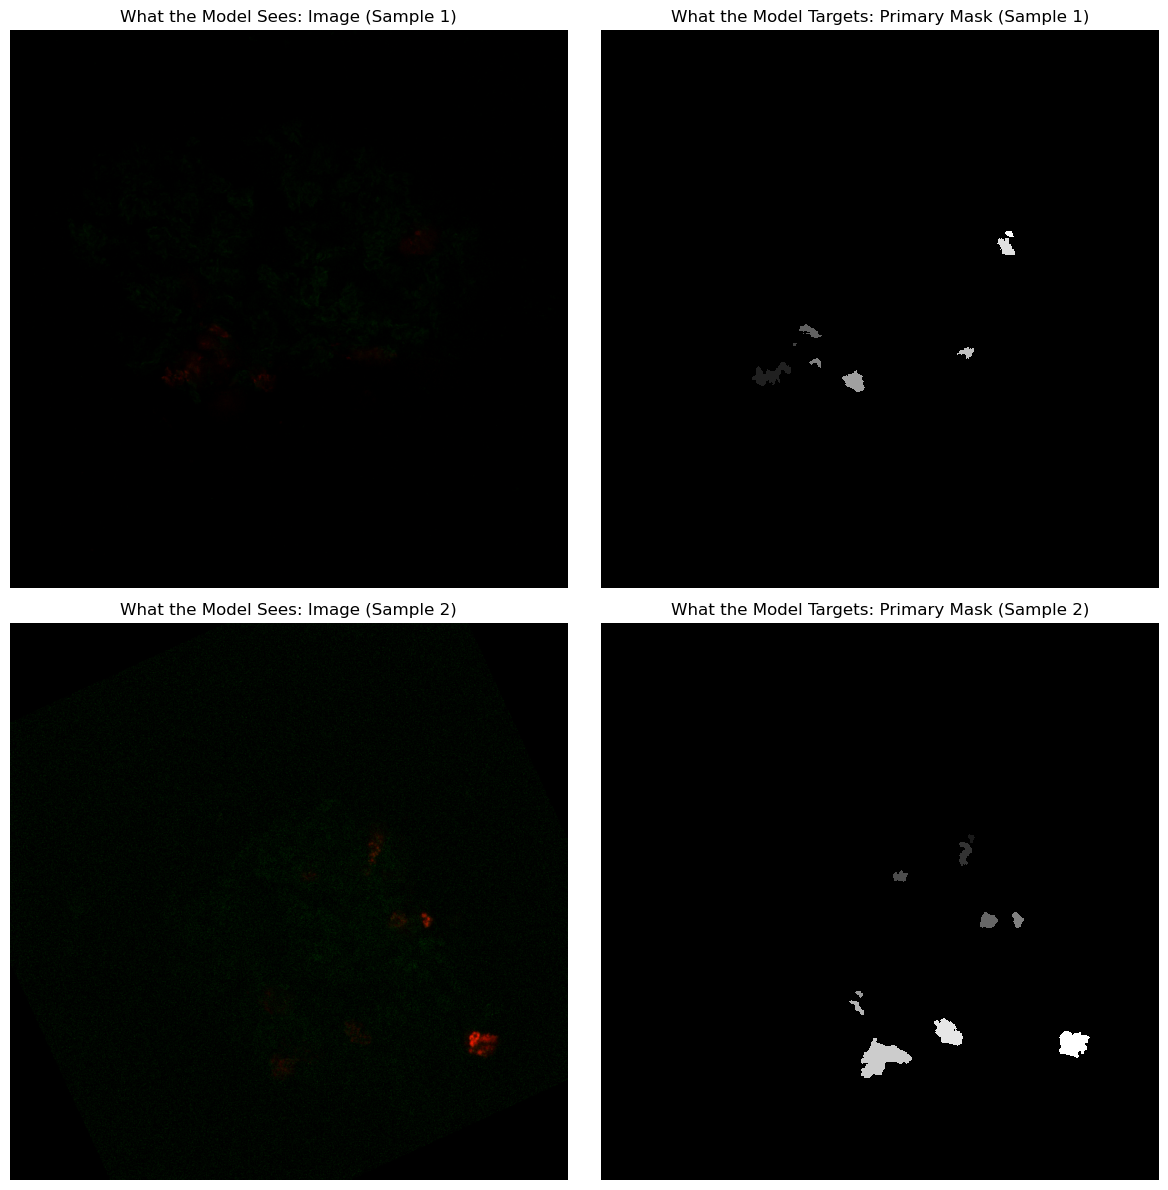

In [10]:
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch_em
from torchvision.transforms import Compose
from torch_em.transform.augmentation import KorniaAugmentationPipeline
import kornia.augmentation as K
from micro_sam.training import default_sam_loader

print("--- Setting up the Real DataLoader ---")

# 1. Define the exact augmentations from your training script
geometric_augmentations = KorniaAugmentationPipeline(
    K.RandomHorizontalFlip(p=0.5),
    K.RandomVerticalFlip(p=0.5),
    K.RandomRotation(degrees=90, p=0.5, resample='nearest'),
    K.RandomElasticTransform(p=0.3, resample='nearest'),
)

class ChannelSafeIntensityAug:
    def __call__(self, x):
        for c in range(2): # Fixed to range(2) as discussed!
            if np.random.rand() > 0.5:
                x[c] = x[c] + np.random.randn(*x[c].shape) * 0.05
            if np.random.rand() > 0.5:
                factor = np.random.uniform(0.8, 1.2)
                x[c] = np.clip(x[c] * factor, 0, 1)
        return x

def clip_to_one(x):
    return np.clip(x, 0, 1)

def scale_to_255(x):
    return x * 255

intensity_and_scale_transform = Compose([
    ChannelSafeIntensityAug(),
    clip_to_one,     
    scale_to_255               
])

# 2. Initialize the exact DataLoader used in training
sampler = torch_em.data.sampler.MinForegroundSampler(min_fraction=0.001)

# Note: train_raw and train_lbl are already defined in Cell 5 of your notebook
train_loader = default_sam_loader(
    raw_paths=train_raw,
    raw_key=None,
    label_paths=train_lbl,
    label_key=None,
    patch_shape=(1024, 1024),
    batch_size=2, # Set to 2 just to see a couple of examples
    with_segmentation_decoder=True,
    shuffle=True,
    sampler=sampler,
    raw_transform=intensity_and_scale_transform,
    transform=geometric_augmentations,
)

# 3. Define the Interceptor Function
def visualize_what_model_sees(dataloader, num_samples=2):
    print("\n--- Intercepting a Live Batch from the DataLoader ---")
    
    # Fetch exactly one batch from the generator
    images, masks = next(iter(dataloader))
    
    print(f"Batch Image Tensor: shape={images.shape}, dtype={images.dtype}, range=[{images.min():.2f}, {images.max():.2f}]")
    print(f"Batch Mask Tensor:  shape={masks.shape}, dtype={masks.dtype}, range=[{masks.min():.2f}, {masks.max():.2f}]\n")
    
    batch_size = images.shape[0]
    n_display = min(num_samples, batch_size)
    
    fig, axes = plt.subplots(n_display, 2, figsize=(12, 6 * n_display))
    if n_display == 1: axes = [axes]
        
    for i in range(n_display):
        # -- Process Image --
        # PyTorch is (C, H, W). Matplotlib expects (H, W, C)
        img_np = images[i].cpu().numpy()
        img_display = np.transpose(img_np, (1, 2, 0))
        
        # Safely cast to uint8 for visualization
        if img_display.max() > 1.0:
            img_display = img_display.astype(np.uint8)
        else:
            img_display = np.clip(img_display, 0, 1)
            
        # -- Process Mask --
        mask_np = masks[i].cpu().numpy()
        
        # THE FIX: Extract just the 1st channel, which is your single-channel ground truth mask.
        # This results in a perfect 2D array of (1024, 1024)
        mask_display = mask_np[0] 
        
        # Plot Image
        axes[i][0].imshow(img_display)
        axes[i][0].set_title(f"What the Model Sees: Image (Sample {i+1})")
        axes[i][0].axis('off')
        
        # Plot Mask (Added cmap='gray' back in so it renders clearly as black/white)
        axes[i][1].imshow(mask_display, cmap='gray', interpolation='nearest')
        axes[i][1].set_title(f"What the Model Targets: Primary Mask (Sample {i+1})")
        axes[i][1].axis('off')
        
    plt.tight_layout()
    plt.show()

# Run the visualization!
visualize_what_model_sees(train_loader)

In [8]:
sample_mask_path = r"/home/students/rawat/training_data/training_data_DOG/train/masks/Brain4_1340_Cont_AiryscanSR_Fly2_CalyxR_1100_slice_0009.tif"
sample_mask = tifffile.imread(sample_mask_path)
print(f"Shape of mask  = {sample_mask.shape}, dtype={sample_mask.dtype}, unique values={np.unique(sample_mask)}")

Shape of mask  = (1100, 1100), dtype=uint16, unique values=[0 1 2 3 4 5 6 7]



--- Running Traceable Augmentation Pipeline ---


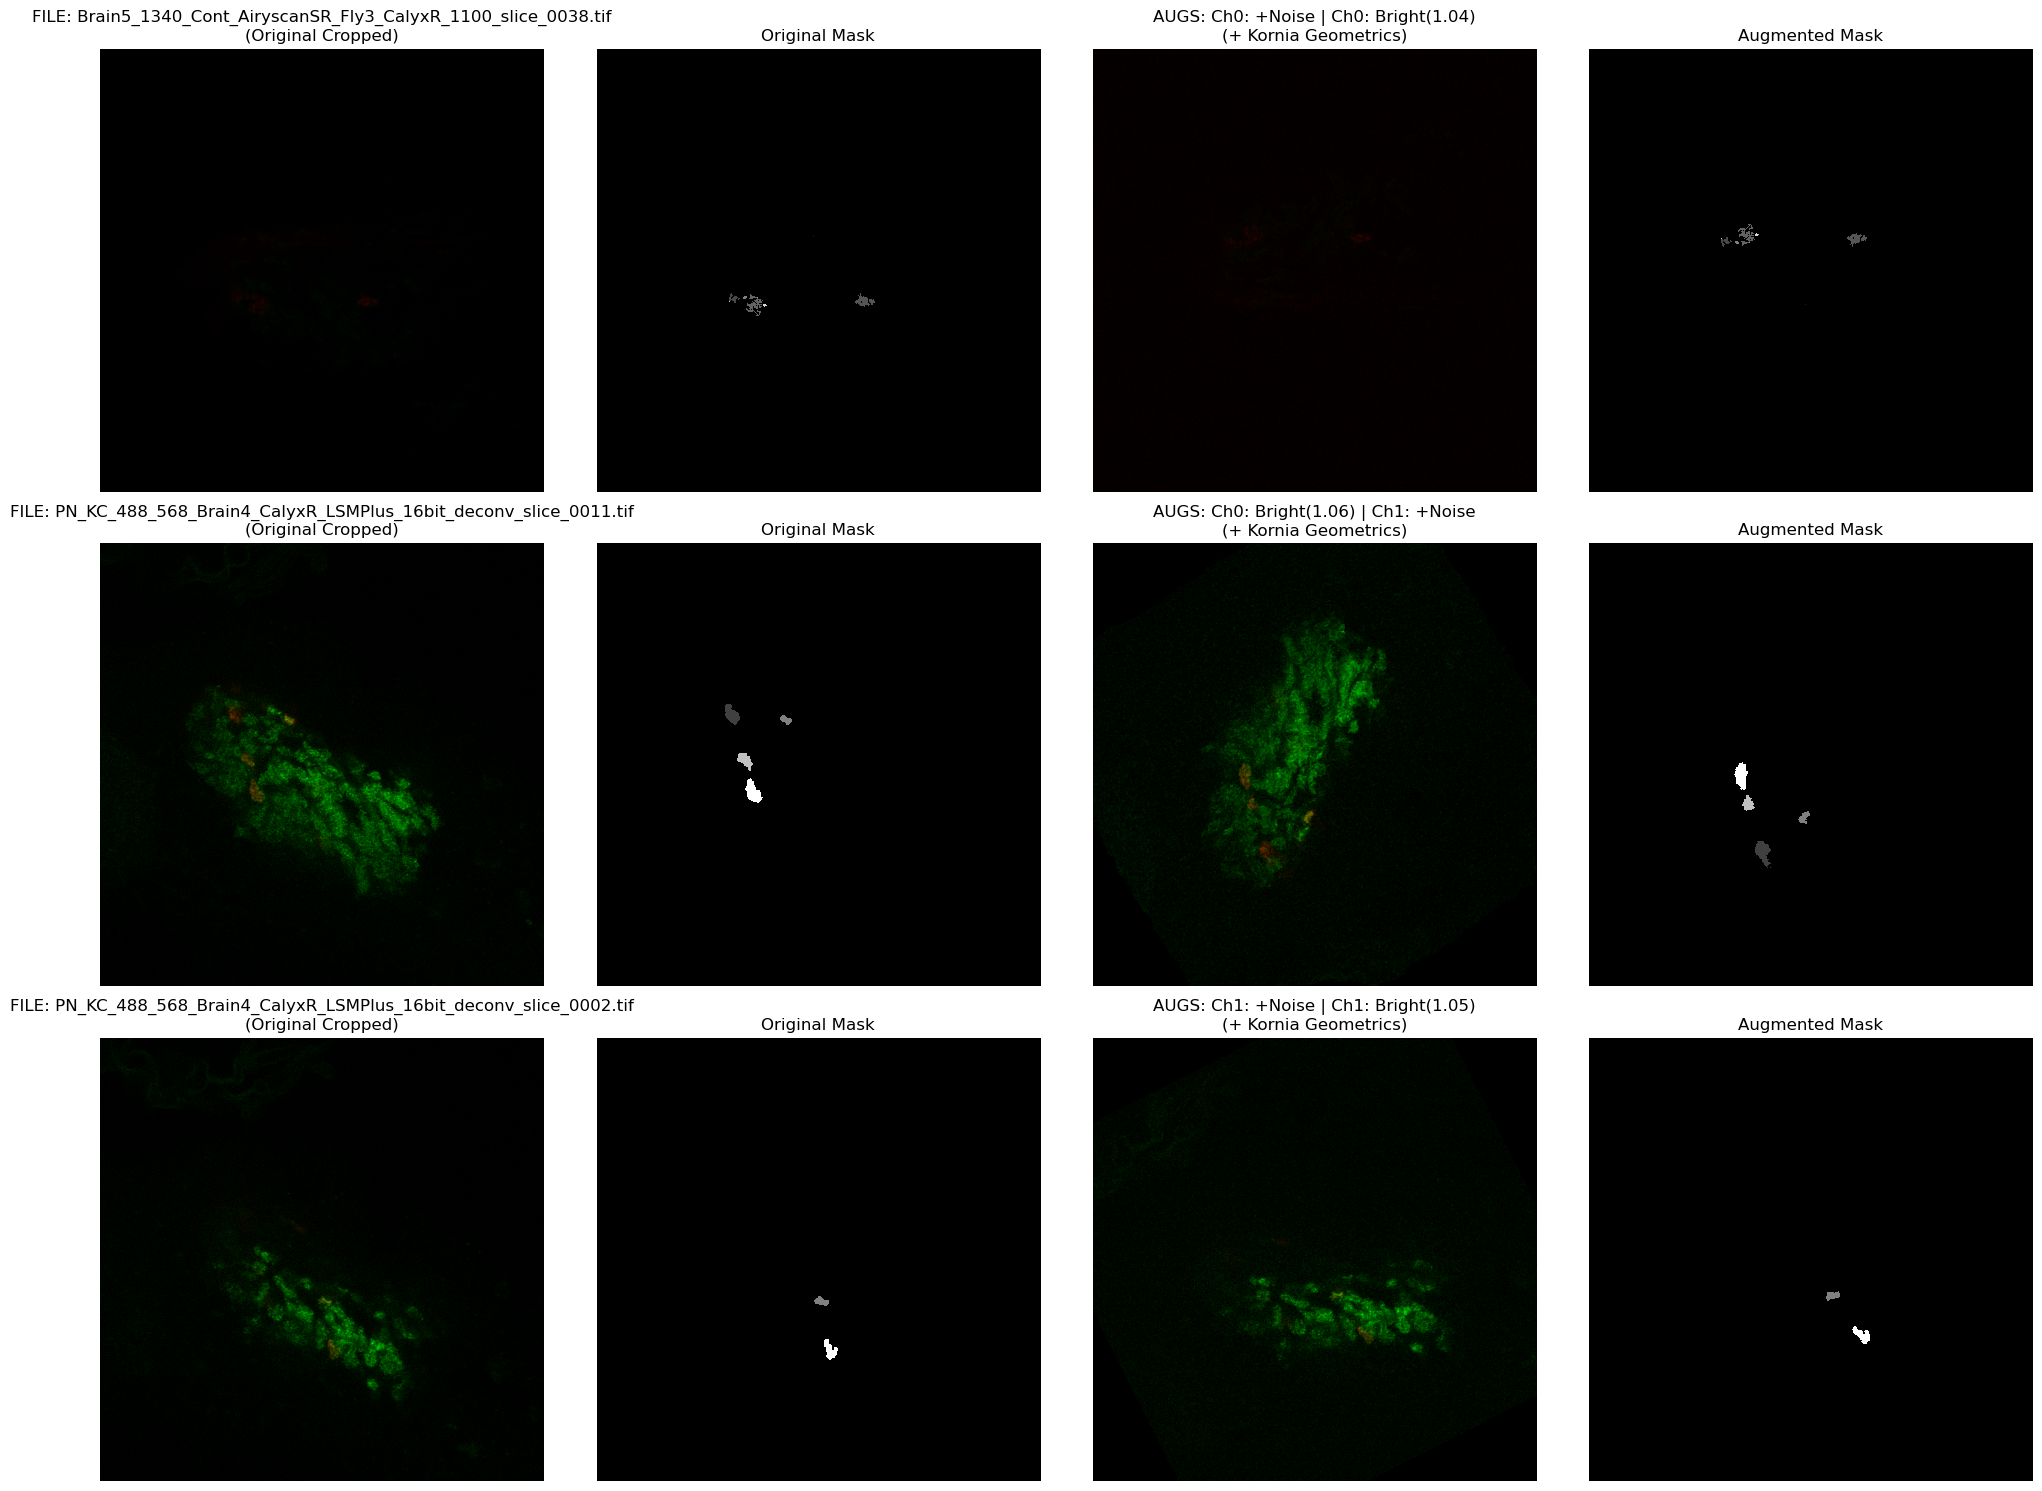

In [14]:
import random
import os
import tifffile
import torch
import numpy as np
import matplotlib.pyplot as plt
from torchvision.transforms import Compose
from torch_em.transform.augmentation import KorniaAugmentationPipeline
import kornia.augmentation as K

# --- 1. Helper Functions ---
def stretch_contrast(img):
    """Stretch contrast of a float image for better visualization."""
    p2, p98 = np.percentile(img, (2, 98))
    # Prevent division by zero if image is completely black
    if p98 == p2:
        return np.clip(img, 0, 1)
    img_rescale = (img - p2) / (p98 - p2)
    return np.clip(img_rescale, 0, 1)

def clip_to_one(x):
    return np.clip(x, 0, 1)

def scale_to_255(x):
    return x * 255

# --- 2. Defining the Augmentations ---
geometric_augmentations = KorniaAugmentationPipeline(
    K.RandomHorizontalFlip(p=0.5),
    K.RandomVerticalFlip(p=0.5),
    K.RandomRotation(degrees=90, p=0.5, resample='nearest'),
    K.RandomElasticTransform(p=0.3, resample='nearest'),
)

class LoggingChannelSafeIntensityAug:
    def __init__(self):
        self.last_log = "" # Store the applied transforms here
        
    def __call__(self, x):
        logs = []
        for c in range(2): # Apply only to channels 0 and 1
            if np.random.rand() > 0.5:
                x[c] = x[c] + np.random.randn(*x[c].shape) * 0.05
                logs.append(f"Ch{c}: +Noise")
            if np.random.rand() > 0.5:
                factor = np.random.uniform(0.8, 1.2)
                x[c] = np.clip(x[c] * factor, 0, 1)
                logs.append(f"Ch{c}: Bright({factor:.2f})")
        
        self.last_log = " | ".join(logs) if logs else "None"
        return x

# --- 3. The Traceable Visualization Function ---
def visualize_traceable_samples(image_paths, mask_paths, num_samples=2):
    print("\n--- Running Traceable Augmentation Pipeline ---")
    
    # Initialize our logging transform
    logging_intensity_aug = LoggingChannelSafeIntensityAug()
    
    # Combine intensity transforms and scaling
    test_transform = Compose([
        logging_intensity_aug,
        clip_to_one,
        scale_to_255
    ])
    
    fig, axes = plt.subplots(num_samples, 4, figsize=(20, 5 * num_samples))
    if num_samples == 1: axes = [axes]
        
    for i in range(num_samples):
        # Pick a random file index
        idx = random.randint(0, len(image_paths) - 1)
        img_path = image_paths[idx]
        mask_path = mask_paths[idx]
        file_name = os.path.basename(img_path)
        
        # Load the data
        img = tifffile.imread(img_path)
        mask = tifffile.imread(mask_path)
        
        # Simulate the Dataloader's patch cropping (1024x1024)
        h, w = img.shape[:2]
        if h > 1024 or w > 1024:
            top = random.randint(0, h - 1024)
            left = random.randint(0, w - 1024)
            img = img[top:top+1024, left:left+1024]
            mask = mask[top:top+1024, left:left+1024]
            
        # Keep originals for plotting 
        orig_img_display = img.copy()
        orig_mask_display = mask.copy()
        
        # -- 1. Apply Intensity Augmentations --
        img_chw = np.transpose(img, (2, 0, 1)).copy()
        img_intensity_applied = test_transform(img_chw)
        
        # Grab the text of what was just applied
        applied_intensity_logs = logging_intensity_aug.last_log 
        
        # -- 2. Apply Geometric Augmentations (Kornia) --
        img_tensor = torch.from_numpy(img_intensity_applied).unsqueeze(0).float()
        mask_tensor = torch.from_numpy(mask).unsqueeze(0).unsqueeze(0).float()
        
        aug_img_tensor, aug_mask_tensor = geometric_augmentations(img_tensor, mask_tensor)
        
        # Prep for final display
        final_img = np.transpose(aug_img_tensor.squeeze(0).cpu().numpy(), (1, 2, 0))
        
        # Safely cast to uint8 for matplotlib
        if final_img.max() > 1.0:
            final_img = final_img.astype(np.uint8)
        else:
            final_img = np.clip(final_img, 0, 1)
            
        # Format the mask cleanly (1024, 1024) for matplotlib
        final_mask_np = aug_mask_tensor.squeeze(0).cpu().numpy()
        if final_mask_np.ndim == 3 and final_mask_np.shape[0] > 1:
            final_mask = final_mask_np[0] # Just in case it has multiple channels
        else:
            final_mask = np.squeeze(final_mask_np)
        
        # --- Plotting ---
        # 1. Original Image
        axes[i][0].imshow(orig_img_display)
        axes[i][0].set_title(f"FILE: {file_name}\n(Original Cropped)")
        axes[i][0].axis('off')
        
        # 2. Original Mask
        axes[i][1].imshow(orig_mask_display, cmap='gray', interpolation='nearest')
        axes[i][1].set_title("Original Mask")
        axes[i][1].axis('off')
        
        # 3. Augmented Image
        axes[i][2].imshow(final_img)
        axes[i][2].set_title(f"AUGS: {applied_intensity_logs}\n(+ Kornia Geometrics)")
        axes[i][2].axis('off')
        
        # 4. Augmented Mask
        axes[i][3].imshow(final_mask, cmap='gray', interpolation='nearest')
        axes[i][3].set_title("Augmented Mask")
        axes[i][3].axis('off')
        
    plt.tight_layout()
    plt.show()

# --- 4. Run the tracker! ---
# (Uses train_raw and train_lbl from Cell 5 of your notebook)
visualize_traceable_samples(train_raw, train_lbl, num_samples=3)

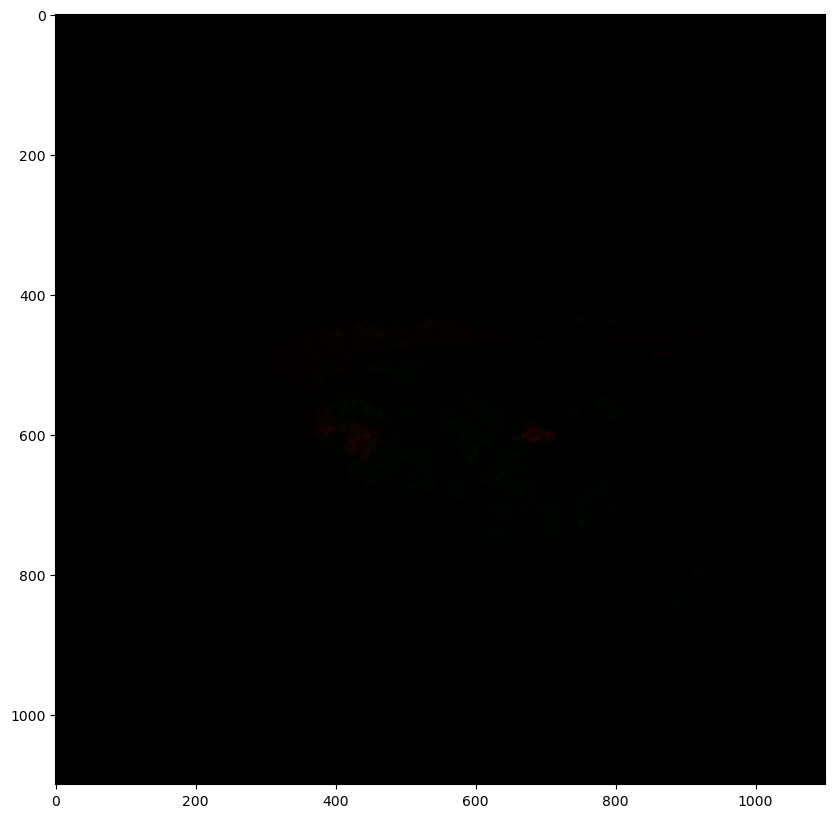

In [16]:
sample_image_path = r"/home/students/rawat/training_data/training_data_DOG/train/images/Brain5_1340_Cont_AiryscanSR_Fly3_CalyxR_1100_slice_0038.tif"
sameple_image = tifffile.imread(sample_image_path)

## visualize the sample image make it big
plt.figure(figsize=(10, 10))
plt.imshow(sameple_image)
